<a href="https://colab.research.google.com/github/datadigger01/Datahandling/blob/main/Code_example/week_09_missingvalue_replacement_cat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('https://github.com/datadigger01/Datahandling/raw/main/Data/default_credit_card_missing.csv',encoding="utf-8-sig")
print(df.info())
df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Cust_ID     30000 non-null  int64  
 1   LIMIT_BAL   30000 non-null  int64  
 2   SEX         30000 non-null  int64  
 3   EDUCATION   27600 non-null  float64
 4   MARRIAGE    27000 non-null  float64
 5   AGE         29700 non-null  float64
 6   PAY_0       30000 non-null  int64  
 7   PAY_2       30000 non-null  int64  
 8   PAY_3       30000 non-null  int64  
 9   PAY_4       30000 non-null  int64  
 10  PAY_5       30000 non-null  int64  
 11  PAY_6       30000 non-null  int64  
 12  BILL_AMT1   30000 non-null  int64  
 13  BILL_AMT2   30000 non-null  int64  
 14  BILL_AMT3   30000 non-null  int64  
 15  BILL_AMT4   30000 non-null  int64  
 16  BILL_AMT5   30000 non-null  int64  
 17  BILL_AMT6   30000 non-null  int64  
 18  PAY_AMT1    30000 non-null  int64  
 19  PAY_AMT2    30000 non-nul

,Cust_ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_YN
0,1,20000,2,2.0,1.0,24.0,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2.0,2.0,26.0,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2.0,2.0,34.0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2.0,1.0,37.0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2.0,1.0,57.0,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000,1,3.0,1.0,39.0,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,29997,150000,1,3.0,NaN,43.0,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,29998,30000,1,2.0,2.0,37.0,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,29999,80000,1,3.0,1.0,41.0,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


In [5]:
# 범주형 변수 missing value 확인
print(df['EDUCATION'].value_counts(dropna=False))
print(df['EDUCATION'].value_counts(dropna=False, normalize=True))

EDUCATION
2.0    12875
1.0     9786
3.0     4511
NaN     2400
5.0      259
4.0      111
6.0       46
0.0       12
Name: count, dtype: int64
EDUCATION
2.0    0.429167
1.0    0.326200
3.0    0.150367
NaN    0.080000
5.0    0.008633
4.0    0.003700
6.0    0.001533
0.0    0.000400
Name: proportion, dtype: float64


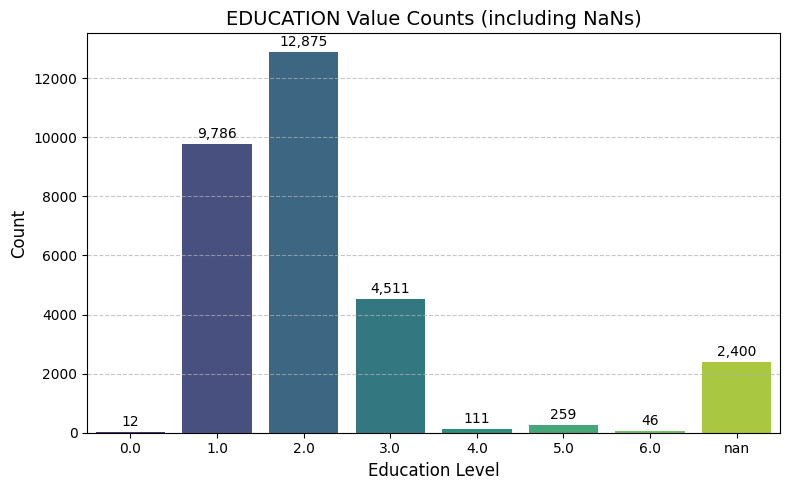

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# EDUCATION 값별 빈도 계산 (결측값 포함)
education_counts = df['EDUCATION'].value_counts(dropna=False).sort_index()

# 막대그래프 시각화
plt.figure(figsize=(8, 5))
sns.barplot(x=education_counts.index.astype(str), y=education_counts.values, palette='viridis', hue=education_counts.index.astype(str), legend=False)

plt.title('EDUCATION Value Counts (including NaNs)', fontsize=14)
plt.xlabel('Education Level', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 각 막대 위에 빈도값 표시
for i, val in enumerate(education_counts.values):
    plt.text(i, val + 100, f'{val:,}' if not np.isnan(val) else f'{val}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

###  kNN을 이용한 EDUCATION 결측값 대체 (Model-based Imputation)

#### - 핵심 아이디어
  - EDUCATION이 관측된 행(학습용)으로 kNN 분류모형을 만들고,
  - EDUCATION이 결측인 행의 값을 '가장 가까운 k명의 이웃' 다수결로 예측해 채운다.
  - EDUCATION은 범주형이므로 이웃의 '평균'이 아니라 '최빈값(다수결)'을 사용하여 채운 결과와 비교한다.

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

# ─────────────────────────────────────────────
# [1단계] 결측 현황 확인
# ─────────────────────────────────────────────
# df = pd.read_csv("default_credit_card_missing.csv", encoding="utf-8-sig")
print("[1단계] 결측 현황")
print(df.isna().sum()[df.isna().sum() > 0], "\n")

[1단계] 결측 현황
EDUCATION    2400
MARRIAGE     3000
AGE           300
dtype: int64 



In [8]:
# ─────────────────────────────────────────────
# [2단계] 예측에 사용할 변수(특성) 선택
#   - 결측이 없는 변수만 사용: LIMIT_BAL, PAY_*, BILL_AMT*, PAY_AMT*
#   - 제외: Cust_ID(식별자), default_YN(이후 분석의 목표변수 → 정보 누설 방지),
#           SEX/MARRIAGE/AGE(이들 자체에도 결측이 있음)
# ─────────────────────────────────────────────
target = "EDUCATION"
features = (["LIMIT_BAL"]
            + ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
            + [f"BILL_AMT{i}" for i in range(1, 7)]
            + [f"PAY_AMT{i}" for i in range(1, 7)])
print(f"[2단계] 사용 변수 {len(features)}개:", features, "\n")

[2단계] 사용 변수 19개: ['LIMIT_BAL', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'] 



In [9]:
# ─────────────────────────────────────────────
# [3단계] 관측 행 / 결측 행 분리
# ─────────────────────────────────────────────
is_na = df[target].isna()
X_obs, y_obs = df.loc[~is_na, features], df.loc[~is_na, target].astype(int)
X_mis = df.loc[is_na, features]
print(f"[3단계] 관측 행 {len(X_obs):,}개 / 결측 행 {len(X_mis):,}개\n")

[3단계] 관측 행 27,600개 / 결측 행 2,400개



In [10]:
# ─────────────────────────────────────────────
# [4단계] 표준화 + kNN 파이프라인 구성
#   kNN은 거리 기반이므로 척도가 큰 변수(BILL_AMT 등)가 거리를 지배하지 않도록
#   반드시 표준화(평균 0, 표준편차 1)를 먼저 한다.
# ─────────────────────────────────────────────
def make_model(k):
    return make_pipeline(StandardScaler(),
                         KNeighborsClassifier(n_neighbors=k, weights="distance"))

In [11]:
# ─────────────────────────────────────────────
# [5단계] 교차검증으로 최적의 k 선택 (관측 행만 사용)
# ─────────────────────────────────────────────
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1245)
k_list = [1, 3, 5, 7, 11, 15, 21, 30, 40, 50, 60, 70, 80]
cv_result = {}
print("[5단계] k별 5-fold 교차검증 정확도")
for k in k_list:
    score = cross_val_score(make_model(k), X_obs, y_obs, cv=cv,
                            scoring="accuracy").mean()
    cv_result[k] = score
    print(f"  k={k:>2}: {score:.4f}")
best_k = max(cv_result, key=cv_result.get)
print(f"  → 선택된 k = {best_k}\n")

[5단계] k별 5-fold 교차검증 정확도
  k= 1: 0.4101
  k= 3: 0.4304
  k= 5: 0.4476
  k= 7: 0.4621
  k=11: 0.4781
  k=15: 0.4888
  k=21: 0.4999
  k=30: 0.5058
  k=40: 0.5138
  k=50: 0.5158
  k=60: 0.5185
  k=70: 0.5199
  k=80: 0.5187
  → 선택된 k = 70



In [12]:
# ─────────────────────────────────────────────
# [6단계] 최적 k로 학습 후 결측 행 예측 → 대체
# ─────────────────────────────────────────────
model = make_model(best_k).fit(X_obs, y_obs)
df_imp = df.copy()
df_imp.loc[is_na, target] = model.predict(X_mis)
df_imp[target] = df_imp[target].astype("Int64")
print("[6단계] 대체 후 EDUCATION 결측 개수:", df_imp[target].isna().sum(), "\n")

[6단계] 대체 후 EDUCATION 결측 개수: 0 



In [13]:
# ─────────────────────────────────────────────
# [7단계] 대체 결과 평가 (실습용: 원본에 정답이 남아 있음)
#   비교 기준: 가장 단순한 최빈값 대체
# ─────────────────────────────────────────────
orig = pd.read_csv('https://github.com/datadigger01/datamining/raw/main/DATA/default_credit_card.csv', encoding="utf-8-sig")
y_true = orig.loc[is_na, target]
y_knn = df_imp.loc[is_na, target].astype(int)
y_mode = np.full(len(y_true), y_obs.mode()[0])

print("[7단계] 결측 위치에서의 대체 정확도")
print(f"  최빈값 대체 : {accuracy_score(y_true, y_mode):.4f}")
print(f"  kNN 대체    : {accuracy_score(y_true, y_knn):.4f}\n")

labels = sorted(orig[target].unique())
cm = pd.DataFrame(confusion_matrix(y_true, y_knn, labels=labels),
                  index=[f"실제{v}" for v in labels],
                  columns=[f"대체{v}" for v in labels])
print("  혼동행렬 (행=실제값, 열=kNN 대체값)")
print(cm, "\n")

# 분포 비교: 대체가 원래 분포를 얼마나 유지하는지
dist = pd.DataFrame({
    "원본(%)": orig[target].value_counts(normalize=True).sort_index() * 100,
    "kNN대체후(%)": df_imp[target].value_counts(normalize=True).sort_index() * 100,
}).round(2)
print("  EDUCATION 분포 비교")
print(dist, "\n")

[7단계] 결측 위치에서의 대체 정확도
  최빈값 대체 : 0.4813
  kNN 대체    : 0.5267

  혼동행렬 (행=실제값, 열=kNN 대체값)
     대체0  대체1  대체2  대체3  대체4  대체5  대체6
실제0    0    2    0    0    0    0    0
실제1    0  357  440    2    0    0    0
실제2    0  244  905    6    0    0    0
실제3    0   81  323    2    0    0    0
실제4    0    5    7    0    0    0    0
실제5    0   10   11    0    0    0    0
실제6    0    0    5    0    0    0    0 

  EDUCATION 분포 비교
           원본(%)  kNN대체후(%)
EDUCATION                  
0           0.05       0.04
1          35.28      34.95
2          46.77      48.55
3          16.39      15.07
4           0.41       0.37
5           0.93       0.86
6           0.17       0.15 



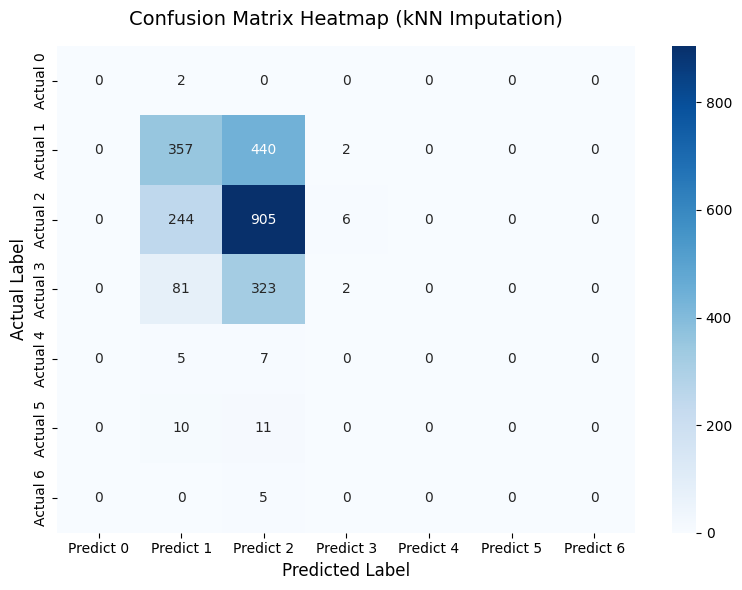

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# 혼돈행렬 시각화 (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=[f'Predict {v}' for v in labels],
            yticklabels=[f'Actual {v}' for v in labels])

plt.title('Confusion Matrix Heatmap (kNN Imputation)', fontsize=14, pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.tight_layout()
plt.show()

### kNN을 이용한 MARRIAGE 결측값 대체 (Model-based Imputation)
#### - 핵심 아이디어
  - MARRIAGE 관측된 행(학습용)으로 kNN 분류모형을 만들고,
  - MARRIAGE 결측인 행의 값을 '가장 가까운 k명의 이웃' 다수결로 예측해 채운다.
  - MARRIAGE 범주형이므로 이웃의 '평균'이 아니라 '최빈값(다수결)'을 사용하여 채운 결과와 비교한다.